# EDA - heart disease (cleveland)

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
from src import config, data
clean = data.run()
import json; print(json.dumps(json.loads((config.PROCESSED_DATA_DIR / 'cleaning_report.json').read_text()), indent=2))

{
  "rows_in": 303,
  "missing_in_raw": {
    "ca": 4,
    "thal": 2
  },
  "out_of_range_set_to_nan": {},
  "invalid_codes_set_to_nan": {},
  "duplicates_removed": 0,
  "rows_out": 303,
  "missing_after_cleaning": {
    "ca": 4,
    "thal": 2
  },
  "class_balance": {
    "0": 164,
    "1": 139
  }
}


In [3]:
raw = data.load_raw_data(); print('raw shape', raw.shape); raw.head()

raw shape (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    Int64  
 1   sex       303 non-null    Int64  
 2   cp        303 non-null    Int64  
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    Int64  
 6   restecg   303 non-null    Int64  
 7   thalach   303 non-null    float64
 8   exang     303 non-null    Int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    Int64  
 11  ca        299 non-null    Int64  
 12  thal      301 non-null    Int64  
 13  target    303 non-null    int64  
dtypes: Int64(9), float64(4), int64(1)
memory usage: 35.9 KB


In [5]:
clean.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [6]:
clean.isna().sum()[lambda s: s > 0]

ca      4
thal    2
dtype: int64

plots

In [7]:
from src import eda
summary = eda.run()
{k: v for k, v in summary.items() if k != 'figures'}

{'rows': 303,
 'features': 13,
 'class_counts': {'No disease': 164, 'Disease': 139},
 'top_target_correlations': {'thal': 0.526,
  'ca': 0.46,
  'exang': 0.432,
  'oldpeak': 0.425,
  'thalach': -0.417,
  'cp': 0.414}}

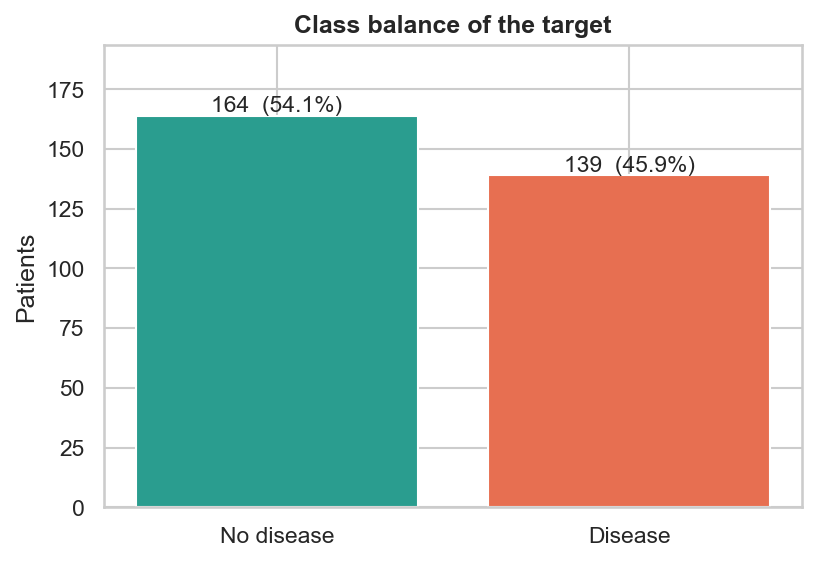

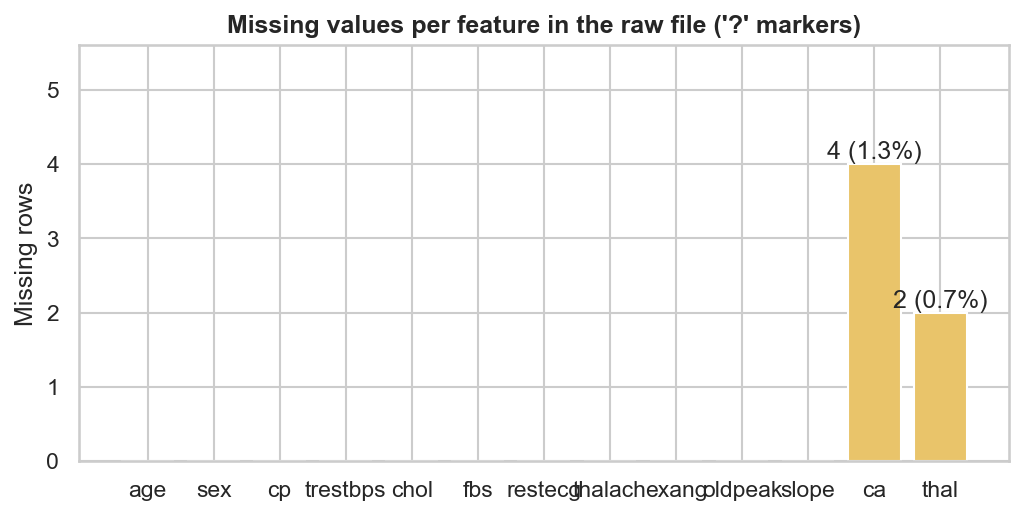

In [8]:
from IPython.display import Image, display
for name in ['01_class_balance.png', '02_missing_values.png']:
    display(Image(filename=str(config.FIGURES_DIR / name), width=520))

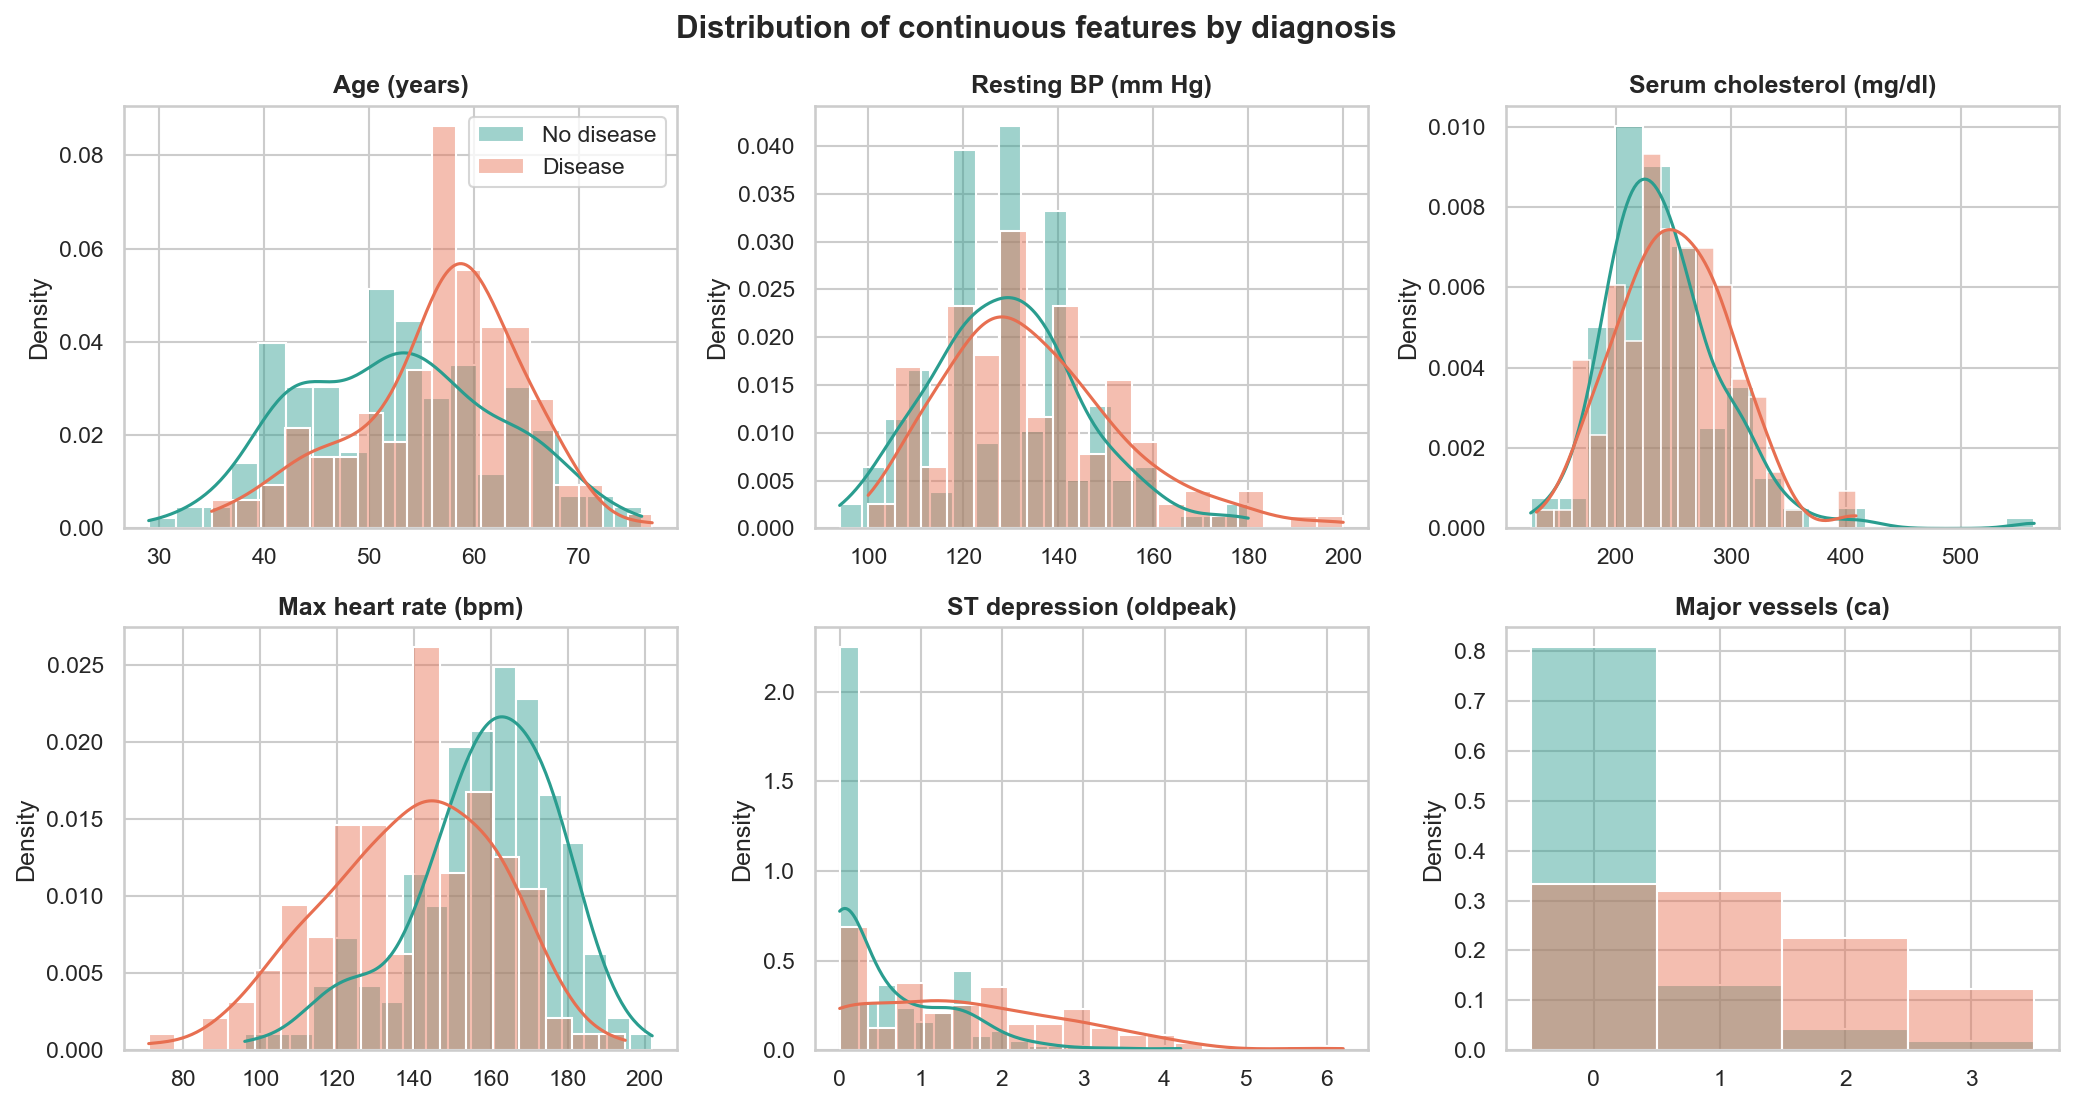

In [9]:
display(Image(filename=str(config.FIGURES_DIR / '03_feature_histograms.png'), width=900))

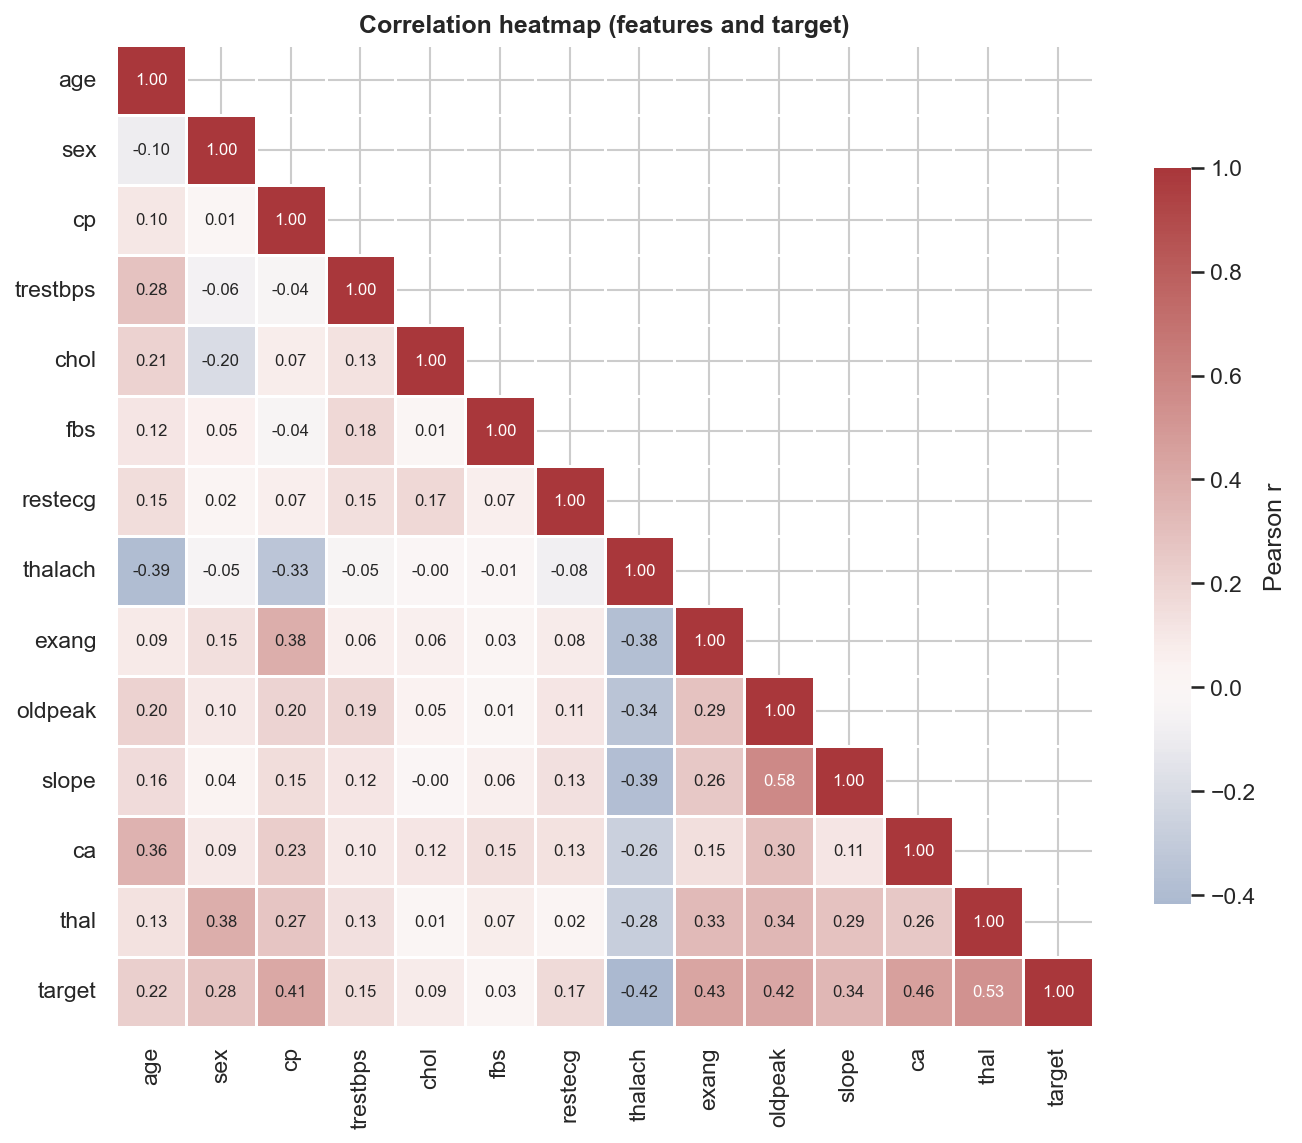

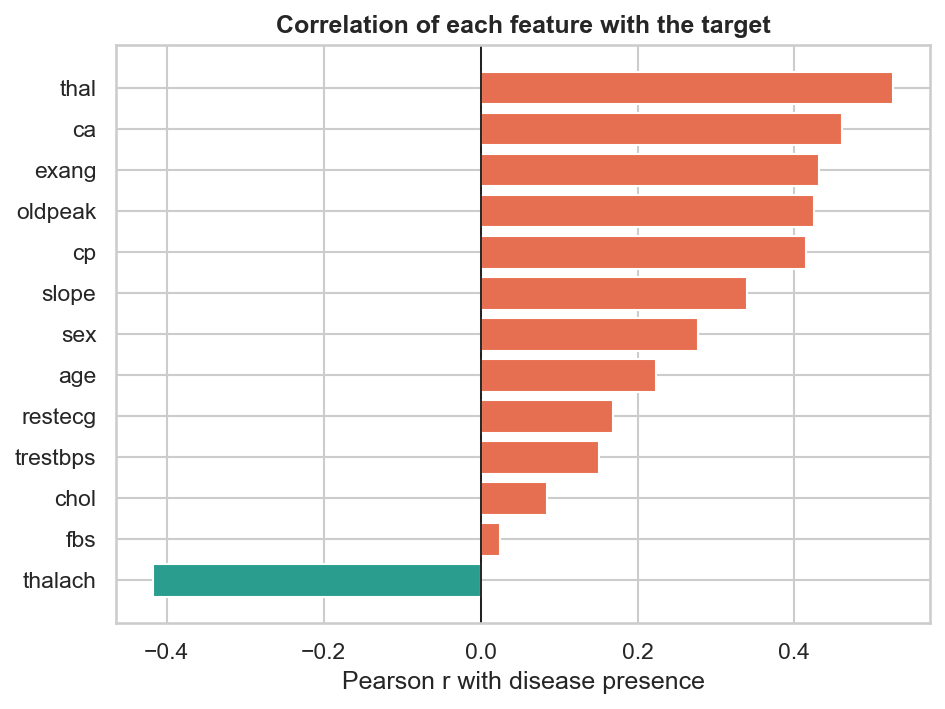

In [10]:
display(Image(filename=str(config.FIGURES_DIR / '04_correlation_heatmap.png'), width=760))
display(Image(filename=str(config.FIGURES_DIR / '05_target_correlation.png'), width=560))

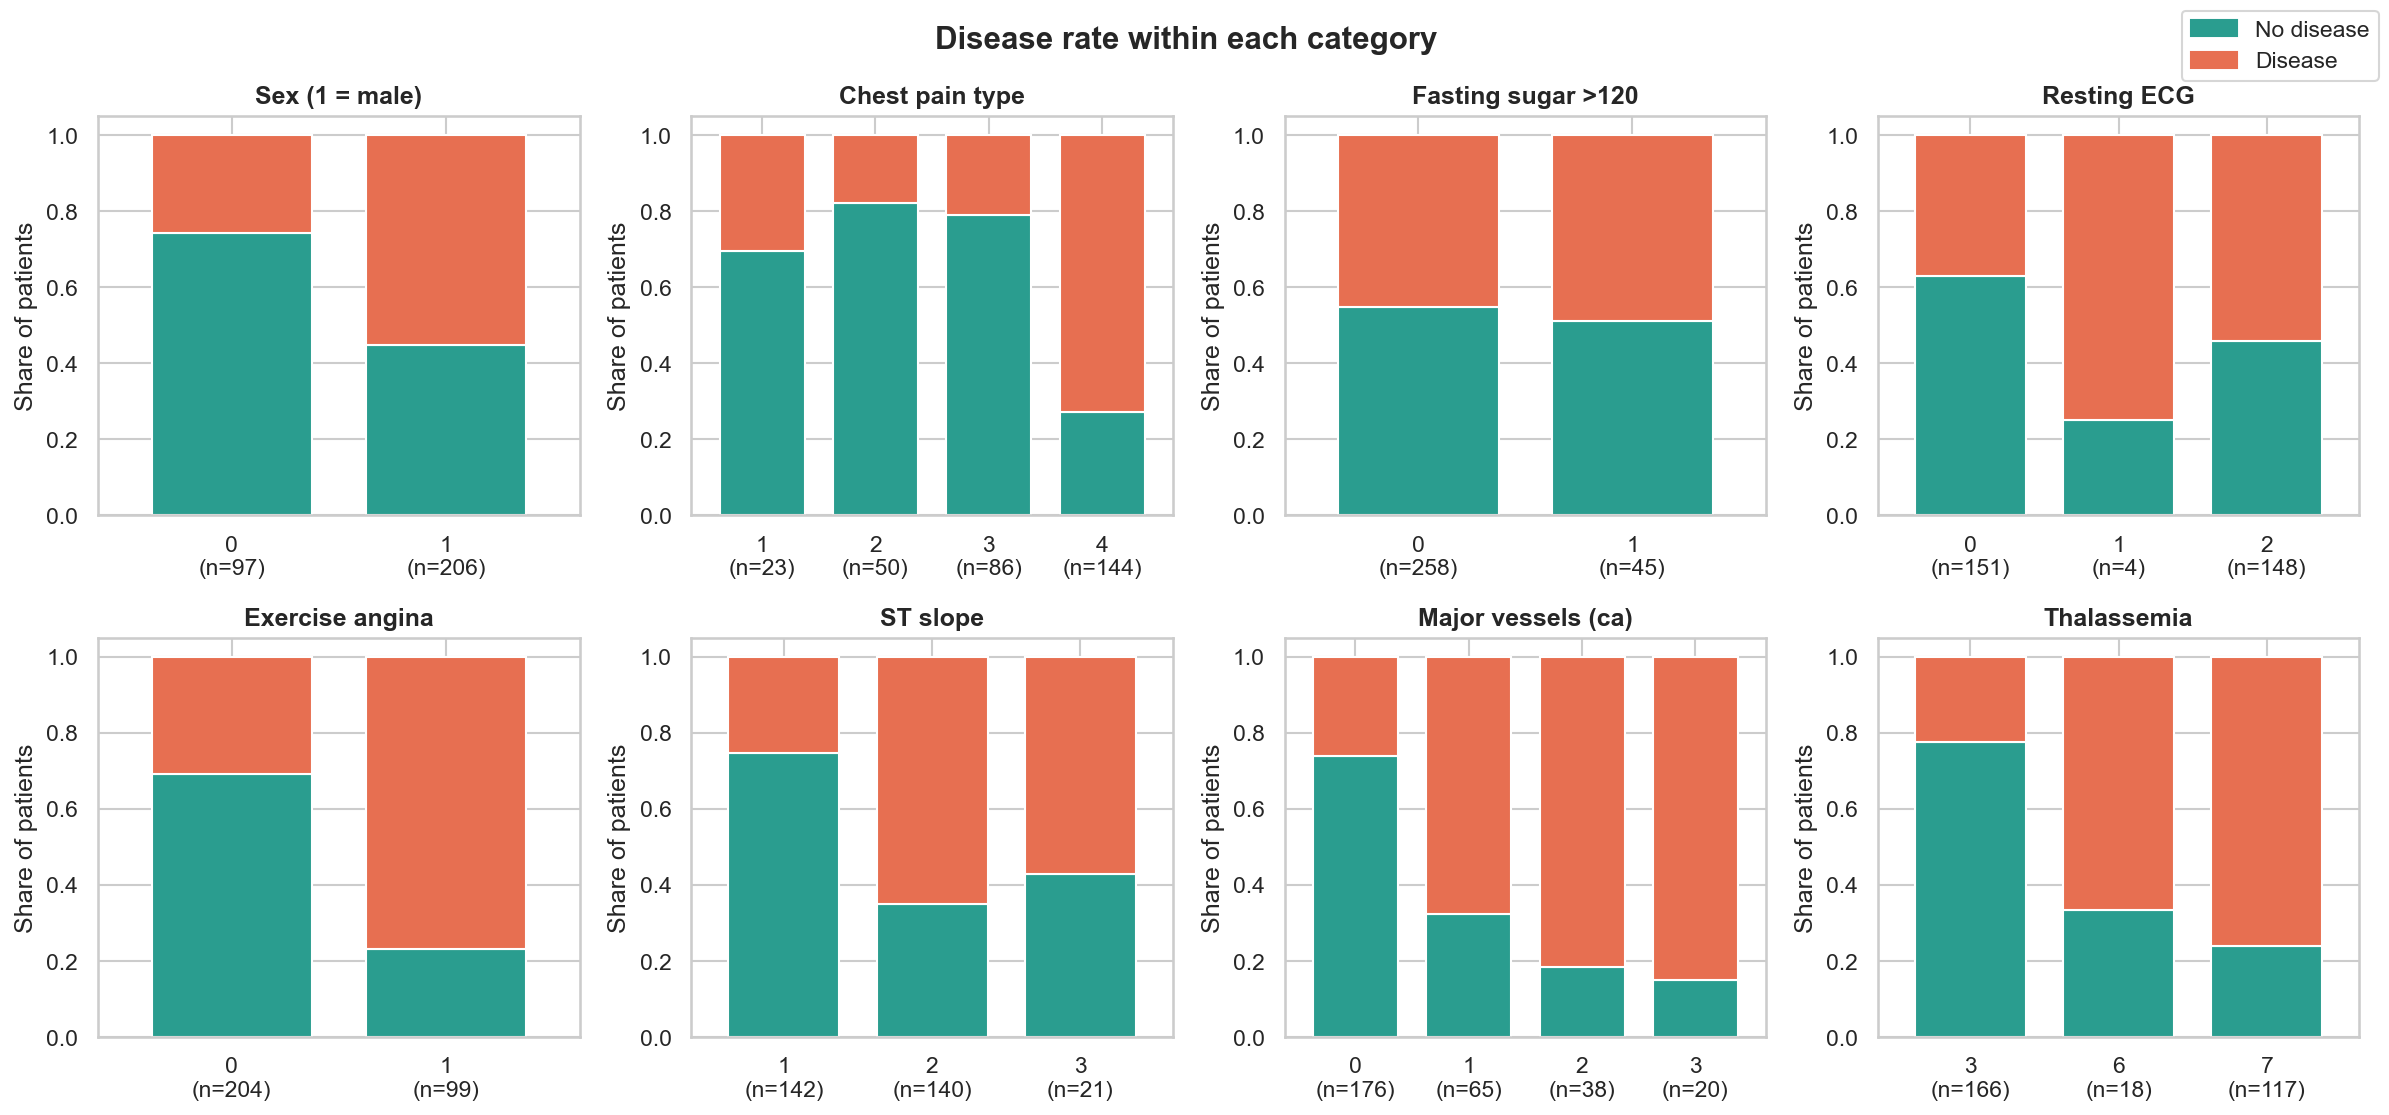

In [11]:
display(Image(filename=str(config.FIGURES_DIR / '06_categorical_disease_rate.png'), width=900))

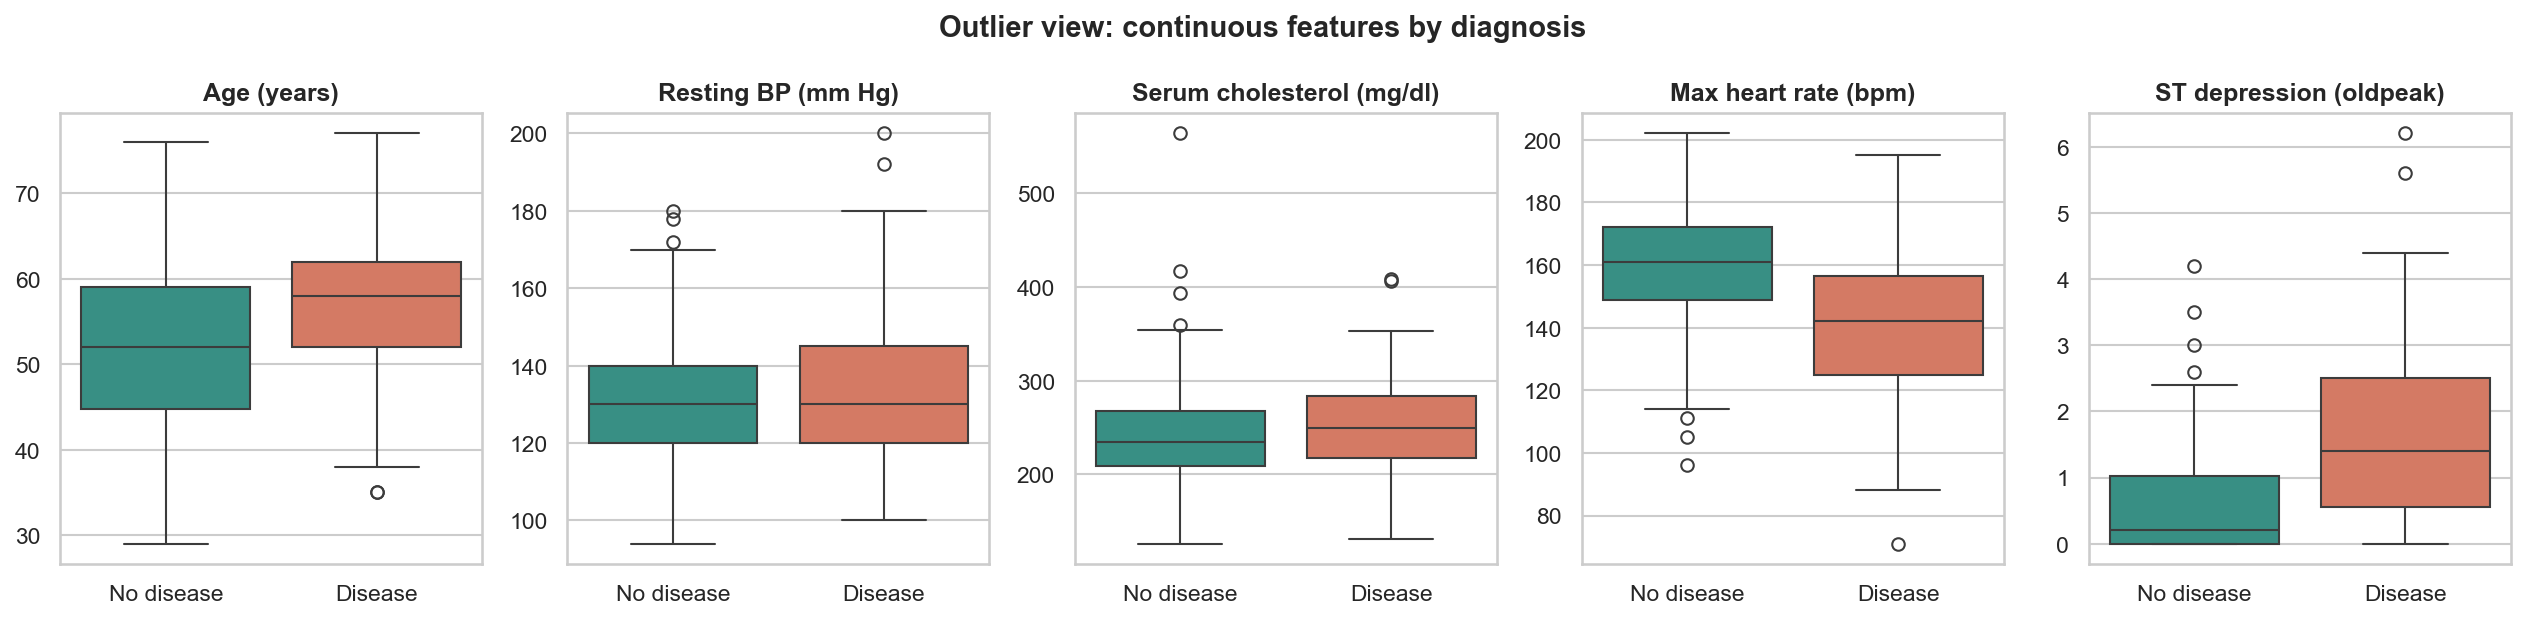

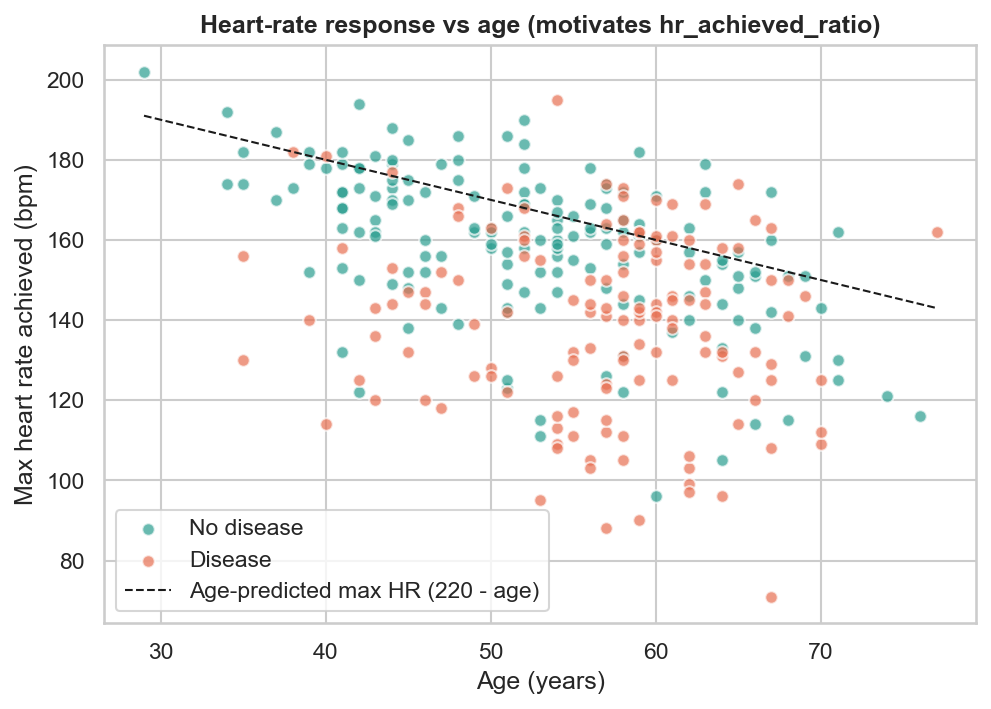

In [12]:
display(Image(filename=str(config.FIGURES_DIR / '07_boxplots.png'), width=900))
display(Image(filename=str(config.FIGURES_DIR / '08_age_vs_max_hr.png'), width=600))

ca and thal have missing values -> imputed in pipeline. classes are almost balanced (164 vs 139). thal, ca, exang, oldpeak, thalach, cp are most related to target.